In [1]:
import os
import cv2
import json
import glob
import tiffslide
import numpy as np
import random
from shapely.geometry import shape, box, Polygon, MultiPolygon
from shapely.affinity import translate

# --- CONFIGURACIÓN ---
RAW_DATA_DIR = os.path.join("C:/Users/paez/Documents/Doct_2026/ratitas_2026")
WSI_IMAGES_DIR = os.path.join(RAW_DATA_DIR, "data/raw/wsi_images")
ANNOTATIONS_DIR = os.path.join(RAW_DATA_DIR, "data/raw/annotations_resized")
OUTPUT_DIR = os.path.join(RAW_DATA_DIR,"data/processed/yolo_dataset")
METADATA_DIR = os.path.join(RAW_DATA_DIR,"data/raw/metadata")
os.makedirs(OUTPUT_DIR, exist_ok=True)

# --- CONFIGURACIÓN ---
RAW_DATA_DIR = "C:/Users/paez/Documents/Doct_2026/ratitas_2026"
WSI_IMAGES_DIR = os.path.join(RAW_DATA_DIR, "data/raw/wsi_images")
ANNOTATIONS_DIR = os.path.join(RAW_DATA_DIR, "data/raw/annotations_resized")
OUTPUT_DIR = os.path.join(RAW_DATA_DIR, "data/processed/yolo_segmentation")

TILE_SIZE = 1024
OVERLAP = 128
TRAIN_RATIO = 0.8  # 80% entrenamiento, 20% validación
random.seed(42)


In [9]:




CLASS_MAP = {
    "Decidua": 0, "Decidual": 0, "dec": 0, "dec1": 0, "dec2": 0,
    "Labyrinth": 1, "lab": 1, "lab1": 1, "lab2": 1,
    "Junctional Zone": 2, "jz": 2, "Junctional": 2
}

def get_yolo_segment_format(geometry, img_w, img_h):
    """Convierte geometría Shapely a string de puntos normalizados para YOLO-SEG."""
    results = []
    
    # Aseguramos que tratamos todo como una lista de geometrías
    if isinstance(geometry, Polygon):
        polys = [geometry]
    elif isinstance(geometry, MultiPolygon):
        polys = geometry.geoms
    else:
        # Si es una LineString o Point producto de la intersección, la ignoramos
        return results
    
    for poly in polys:
        # CORRECCIÓN AQUÍ: .is_empty (con punto y sin el 'inter' pegado)
        if poly.is_empty or not isinstance(poly, Polygon): 
            continue
            
        coords = np.array(poly.exterior.coords)
        
        # Normalizar (0 a 1)
        coords[:, 0] /= img_w
        coords[:, 1] /= img_h
        
        # YOLO necesita al menos 3 puntos para un polígono
        if len(coords) < 3: 
            continue
            
        # Aplanar y convertir a string
        flattened = coords.flatten().tolist()
        results.append(" ".join(map(str, flattened)))
        
    return results

# 1. Crear estructura de carpetas
for split in ['train', 'val']:
    os.makedirs(os.path.join(OUTPUT_DIR, "images", split), exist_ok=True)
    os.makedirs(os.path.join(OUTPUT_DIR, "labels", split), exist_ok=True)

# 2. Split de archivos (por imagen completa)
image_files = sorted(glob.glob(os.path.join(WSI_IMAGES_DIR, "*.tif")))
random.shuffle(image_files)
split_idx = int(len(image_files) * TRAIN_RATIO)
train_files = set(image_files[:split_idx])

print(f"📂 Total imágenes: {len(image_files)} | Train: {len(train_files)} | Val: {len(image_files)-len(train_files)}")

# 3. Bucle Principal
for img_path in image_files:
    base_name = os.path.basename(img_path).replace(".tif", "")
    geojson_path = os.path.join(ANNOTATIONS_DIR, f"{base_name}.geojson")
    current_split = "train" if img_path in train_files else "val"
    
    if not os.path.exists(geojson_path): continue

    print(f"🚜 Procesando {base_name} para {current_split}...")

    with tiffslide.TiffSlide(img_path) as slide:
        w, h = slide.dimensions
        full_img = np.array(slide.read_region((0,0), 0, (w, h)).convert("RGB"))
        full_img = cv2.cvtColor(full_img, cv2.COLOR_RGB2BGR)

    with open(geojson_path, 'r') as f:
        data = json.load(f)
        features = [
            {"geom": shape(f['geometry']), "class": f['properties'].get('name')}
            for f in data.get('features', [])
        ]

    count = 0
    for y in range(0, h - TILE_SIZE + 1, TILE_SIZE - OVERLAP):
        for x in range(0, w - TILE_SIZE + 1, TILE_SIZE - OVERLAP):
            tile_box = box(x, y, x + TILE_SIZE, y + TILE_SIZE)
            tile_labels = []

            for feat in features:
                if tile_box.intersects(feat['geom']):
                    inter = feat['geom'].intersection(tile_box)
                    
                    # Ignorar si la intersección no tiene área (puntos o líneas sueltas)
                    if inter.is_empty or inter.area < 100: continue
                    
                    # Mover polígono al origen del parche
                    local_poly = translate(inter, xoff=-x, yoff=-y)
                    class_id = CLASS_MAP.get(feat['class'], -1)
                    
                    if class_id != -1:
                        yolo_segs = get_yolo_segment_format(local_poly, TILE_SIZE, TILE_SIZE)
                        for seg in yolo_segs:
                            tile_labels.append(f"{class_id} {seg}")

            if tile_labels:
                tile_name = f"{base_name}_tile_{x}_{y}"
                img_out = os.path.join(OUTPUT_DIR, "images", current_split, f"{tile_name}.jpg")
                lbl_out = os.path.join(OUTPUT_DIR, "labels", current_split, f"{tile_name}.txt")
                
                cv2.imwrite(img_out, full_img[y:y+TILE_SIZE, x:x+TILE_SIZE])
                with open(lbl_out, 'w') as f:
                    f.write("\n".join(tile_labels))
                count += 1

    print(f"✅ {base_name}: {count} parches creados.")

# 4. Crear archivo dataset.yaml
yaml_content = f"""
path: {os.path.abspath(OUTPUT_DIR)}
train: images/train
val: images/val

names:
  0: Decidua
  1: Labyrinth
  2: Junctional Zone
"""
with open(os.path.join(OUTPUT_DIR, "dataset.yaml"), "w") as f:
    f.write(yaml_content)

print(f"\n🚀 Proceso terminado. Dataset listo en: {OUTPUT_DIR}")

📂 Total imágenes: 65 | Train: 52 | Val: 13
🚜 Procesando slide_022 para train...
✅ slide_022: 41 parches creados.
🚜 Procesando slide_029 para train...
✅ slide_029: 35 parches creados.
🚜 Procesando slide_001 para train...
✅ slide_001: 39 parches creados.
🚜 Procesando slide_050 para train...
✅ slide_050: 35 parches creados.
🚜 Procesando slide_020 para train...
✅ slide_020: 51 parches creados.
🚜 Procesando slide_026 para train...
✅ slide_026: 20 parches creados.
🚜 Procesando slide_002 para train...
✅ slide_002: 44 parches creados.
🚜 Procesando slide_006 para train...
✅ slide_006: 79 parches creados.
🚜 Procesando slide_040 para train...
✅ slide_040: 33 parches creados.
🚜 Procesando slide_056 para train...
✅ slide_056: 100 parches creados.
🚜 Procesando slide_010 para train...
✅ slide_010: 34 parches creados.
🚜 Procesando slide_017 para train...
✅ slide_017: 33 parches creados.
🚜 Procesando slide_059 para train...
✅ slide_059: 55 parches creados.
🚜 Procesando slide_047 para train...
✅ slide_0

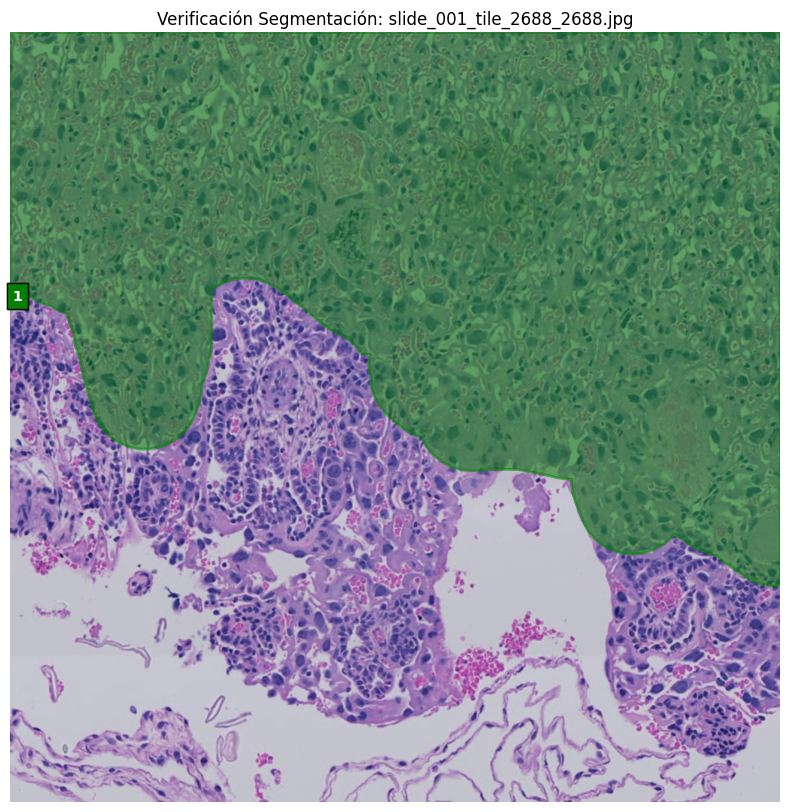

In [3]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

def verify_yolo_segmentation(img_path, label_path):
    # 1. Cargar la imagen del parche
    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    h, w, _ = img.shape
    
    fig, ax = plt.subplots(figsize=(10, 10))
    ax.imshow(img)
    
    # 2. Leer el archivo de labels (.txt)
    if os.path.exists(label_path):
        with open(label_path, 'r') as f:
            lines = f.readlines()
            
        for line in lines:
            data = list(map(float, line.split()))
            class_id = int(data[0])
            # Los puntos vienen en pares x, y normalizados
            points = np.array(data[1:]).reshape(-1, 2)
            
            # Desnormalizar puntos para dibujar sobre la imagen de 1024px
            points[:, 0] *= w
            points[:, 1] *= h
            
            # Crear el polígono para visualizar
            # Usamos un color distinto por clase (0: Rojo, 1: Verde, 2: Azul)
            colors = ['red', 'green', 'blue']
            color = colors[class_id] if class_id < len(colors) else 'yellow'
            
            poly_patch = patches.Polygon(points, closed=True, linewidth=2, 
                                         edgecolor=color, facecolor=color, alpha=0.3)
            ax.add_patch(poly_patch)
            ax.text(points[0,0], points[0,1], str(class_id), color='white', 
                    fontweight='bold', bbox=dict(facecolor=color, alpha=0.8))

    plt.title(f"Verificación Segmentación: {os.path.basename(img_path)}")
    plt.axis('off')
    plt.show()

# --- PRUEBA CON UN PARCHE ALEATORIO ---
# Buscamos en la carpeta de train algún archivo generado
sample_images = glob.glob(os.path.join(OUTPUT_DIR, "images/train/*.jpg"))
if sample_images:
    test_img = sample_images[10]
    test_label = test_img.replace("images", "labels").replace(".jpg", ".txt")
    verify_yolo_segmentation(test_img, test_label)
else:
    print("❌ No se encontraron parches. Asegúrate de correr el script de tiling primero.")